# 01 — Exploratory Data Analysis

**Dataset:** `data/processed/trials.parquet` (one row per interventional trial, AACT, start 2008–2020),
built by `scripts/03_build_dataset.py`.

**Questions this notebook answers**
1. What does the data look like — size, types, missingness, quality problems?
2. How is the outcome distributed (`overall_status`, `stop_reason`, `label`)?
3. Which trial characteristics are associated with being **terminated for low enrollment** (`label = 1`)?
4. Is there early signal that **eligibility criteria** (length, age limits, healthy volunteers) matter?
5. Which columns leak the outcome and must be kept out of the model?

> Rates below are computed on **labeled trials only** (label 1 = terminated for enrollment, 0 = completed),
> unless stated otherwise. `stop_reason` is the v0 keyword classifier, so enrollment-related numbers are provisional.

In [1]:
from pathlib import Path
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = ROOT / "notebooks" / "figures"
FIG.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})
pd.set_option("display.max_columns", 50, "display.width", 140)

def savefig(name):
    plt.savefig(FIG / f"{name}.png", bbox_inches="tight")

df = pd.read_parquet(ROOT / "data" / "processed" / "trials.parquet")
print(f"{len(df):,} trials x {df.shape[1]} columns")
print((ROOT / "data" / "raw" / "SNAPSHOT.txt").read_text())

231,776 trials x 36 columns
Extracted from AACT cloud on 2026-10-07
Cohort: interventional trials with start_date 2008-01-01 to 2020-12-31



## 1. Structure and data types

In [2]:
summary = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "n_unique": df.nunique(),
    "pct_missing": (df.isna().mean() * 100).round(1),
    "example": df.iloc[0],
})
summary

,dtype,n_unique,pct_missing,example
nct_id,str,231776,0.0,NCT01295684
overall_status,str,9,0.0,COMPLETED
why_stopped,str,19409,88.9,NaN
phase,str,8,0.0,NA
start_date,datetime64[ms],4348,0.0,2010-09-30 00:00:00
completion_date,object,6913,1.8,2010-12-31
enrollment,float64,4308,0.1,60.0
enrollment_type,str,2,0.1,ESTIMATED
number_of_arms,float64,36,1.3,2.0
has_dmc,object,2,11.4,False


In [3]:
print("Duplicate nct_id:", df["nct_id"].duplicated().sum())
print("Start date range:", df["start_date"].min().date(), "to", df["start_date"].max().date())

Duplicate nct_id: 0
Start date range: 2008-01-01 to 2020-12-31


## 2. Missingness

Some missingness is structural rather than random, and should be treated as its own category, not imputed:
- `why_stopped` / `stop_reason` only exist for stopped trials.
- `n_collaborators` is missing when a trial has **no** collaborators → this means 0.
- `maximum_age` missing means **no upper age limit**.
- `is_fda_regulated_*` were only added to ClinicalTrials.gov in 2017, so older trials are blank.

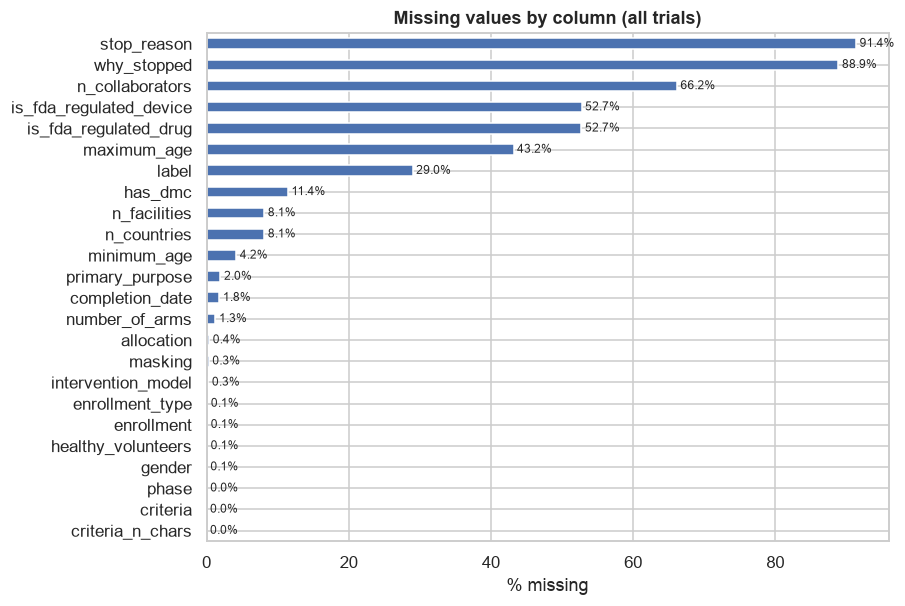

In [4]:
miss = df.isna().mean().sort_values(ascending=False)
miss = miss[miss > 0] * 100
fig, ax = plt.subplots(figsize=(8, 6))
miss.plot.barh(ax=ax, color="#4C72B0")
ax.invert_yaxis()
ax.set_xlabel("% missing")
ax.set_title("Missing values by column (all trials)")
for i, v in enumerate(miss):
    ax.text(v + 0.5, i, f"{v:.1f}%", va="center", fontsize=8)
savefig("missingness"); plt.show()

In [5]:
# FDA-regulated flags: missingness by start year (field introduced Jan 2017)
fda_missing = df.groupby("start_year")["is_fda_regulated_drug"].apply(lambda s: s.isna().mean() * 100)
fda_missing.round(1).to_frame("% missing is_fda_regulated_drug").T

start_year,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020
% missing is_fda_regulated_drug,95.8,95.1,94.4,93.3,91.0,88.5,85.4,78.7,68.4,4.7,0.1,0.1,0.0


## 3. Outcome

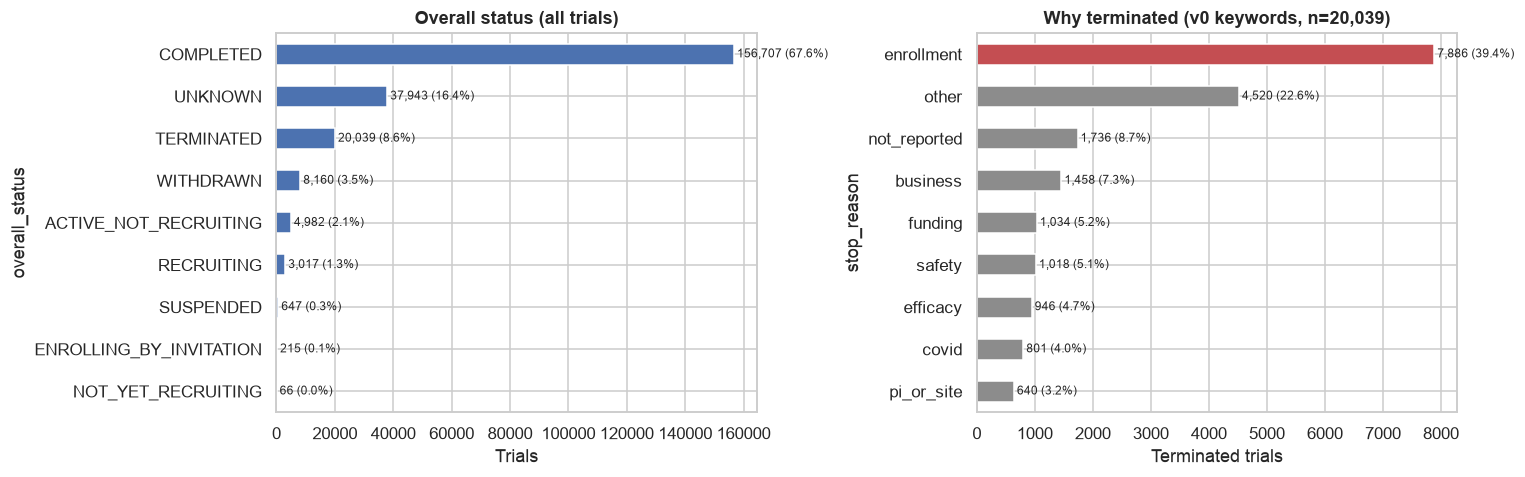

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

status = df["overall_status"].value_counts()
status.plot.barh(ax=axes[0], color="#4C72B0")
axes[0].invert_yaxis()
axes[0].set_title("Overall status (all trials)")
axes[0].set_xlabel("Trials")
for i, v in enumerate(status):
    axes[0].text(v, i, f" {v:,} ({v / len(df):.1%})", va="center", fontsize=8)

reasons = df["stop_reason"].value_counts()
colors = ["#C44E52" if r == "enrollment" else "#8C8C8C" for r in reasons.index]
reasons.plot.barh(ax=axes[1], color=colors)
axes[1].invert_yaxis()
axes[1].set_title(f"Why terminated (v0 keywords, n={reasons.sum():,})")
axes[1].set_xlabel("Terminated trials")
for i, v in enumerate(reasons):
    axes[1].text(v, i, f" {v:,} ({v / reasons.sum():.1%})", va="center", fontsize=8)

plt.tight_layout(); savefig("outcome"); plt.show()

In [7]:
lab = df["label"].map({1: "1 terminated (enrollment)", 0: "0 completed"}).fillna("NaN excluded")
counts = lab.value_counts()
print(counts.to_string())
labeled = df[df["label"].notna()].copy()
print(f"\nPositive rate among labeled trials: {labeled['label'].mean():.2%}")
print(f"Imbalance ratio: 1 : {(labeled['label'] == 0).sum() / (labeled['label'] == 1).sum():.0f}")

label
0 completed                  156707
NaN excluded                  67183
1 terminated (enrollment)      7886

Positive rate among labeled trials: 4.79%
Imbalance ratio: 1 : 20


In [8]:
# Spot-check the v0 keyword classifier: random why_stopped texts per category
for reason in ["enrollment", "other", "business"]:
    print(f"--- {reason} ---")
    s = df.loc[df["stop_reason"] == reason, "why_stopped"].sample(8, random_state=1)
    for t in s:
        print("  •", t[:110])

--- enrollment ---
  • Lack of accrual and funding expires in June, 2014.
  • Accrual not met
  • Slow enrollment and PI departure
  • Recruiting problems
  • Recruitment stopped due to lack of research assistant
  • Recruitment period too long
  • Slow enrollment and planned change of institution by PI
  • Slow inclusion rate (partly due to Covid-19)
--- other ---
  • Terminated due to liver findings
  • unavailability of study device
  • CO2 temperature delivered revealed that warmed CO2 was not being delivered.
  • Drug availability
  • Part 1 completed successfully. Part 2 not conducted.
  • Vapocoolant not effective controlling pain compared with Lidocaine.
  • Due to tolerability issues related to the dose titration, unexpected withdrawals were observed and it was unli
  • We no longer had an appropriate patient population.Study closed
--- business ---
  • The study was terminated early by the sponsor due to strategic reprioritization reasons.
  • A company in China has decided t

## 4. Time trends

The cohort ends in 2020, but trials still running or with `UNKNOWN` status are excluded from the label.
If those are concentrated in recent years, the labeled set is skewed toward trials that finished quickly.

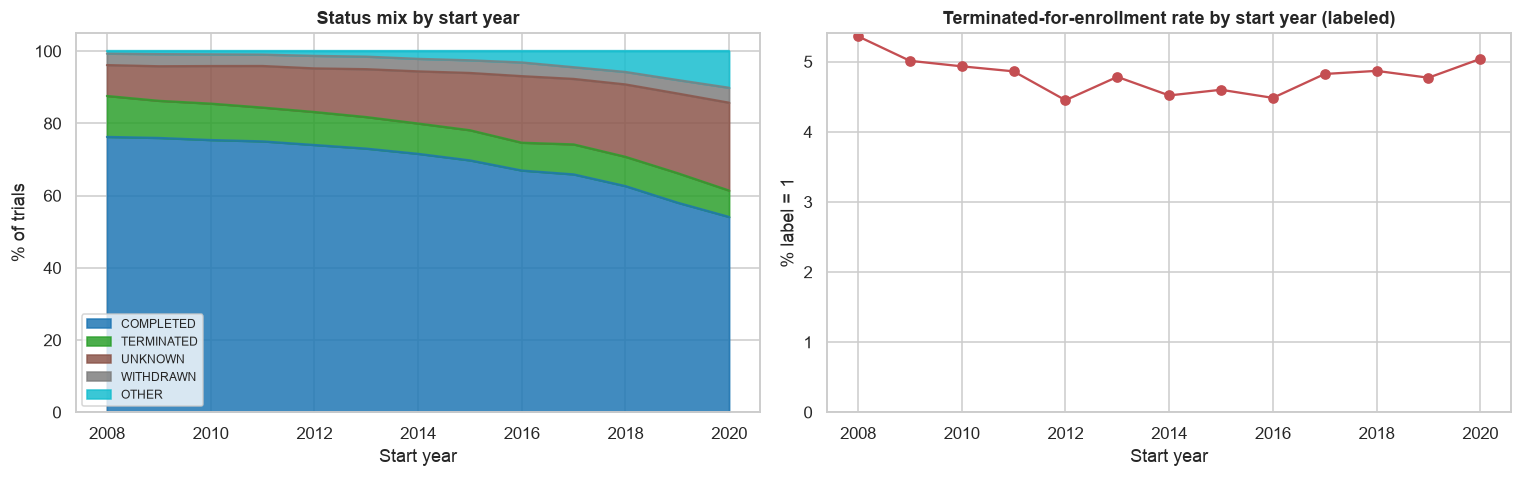

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

status_year = pd.crosstab(df["start_year"], df["overall_status"], normalize="index") * 100
top = ["COMPLETED", "TERMINATED", "UNKNOWN", "WITHDRAWN"]
status_year[top].assign(OTHER=100 - status_year[top].sum(axis=1)).plot.area(
    ax=axes[0], cmap="tab10", alpha=0.85)
axes[0].set_title("Status mix by start year")
axes[0].set_ylabel("% of trials"); axes[0].set_xlabel("Start year")
axes[0].legend(loc="lower left", fontsize=8)

yr = labeled.groupby("start_year")["label"].agg(["mean", "size"])
axes[1].plot(yr.index, yr["mean"] * 100, marker="o", color="#C44E52")
axes[1].set_ylim(0, None)
axes[1].set_title("Terminated-for-enrollment rate by start year (labeled)")
axes[1].set_ylabel("% label = 1"); axes[1].set_xlabel("Start year")

plt.tight_layout(); savefig("time_trends"); plt.show()

## 5. Categorical features vs outcome

Each bar is the share of labeled trials in that category that were terminated for low enrollment,
with a 95% Wilson confidence interval. The dashed line is the overall rate. `n` is the number of labeled trials.

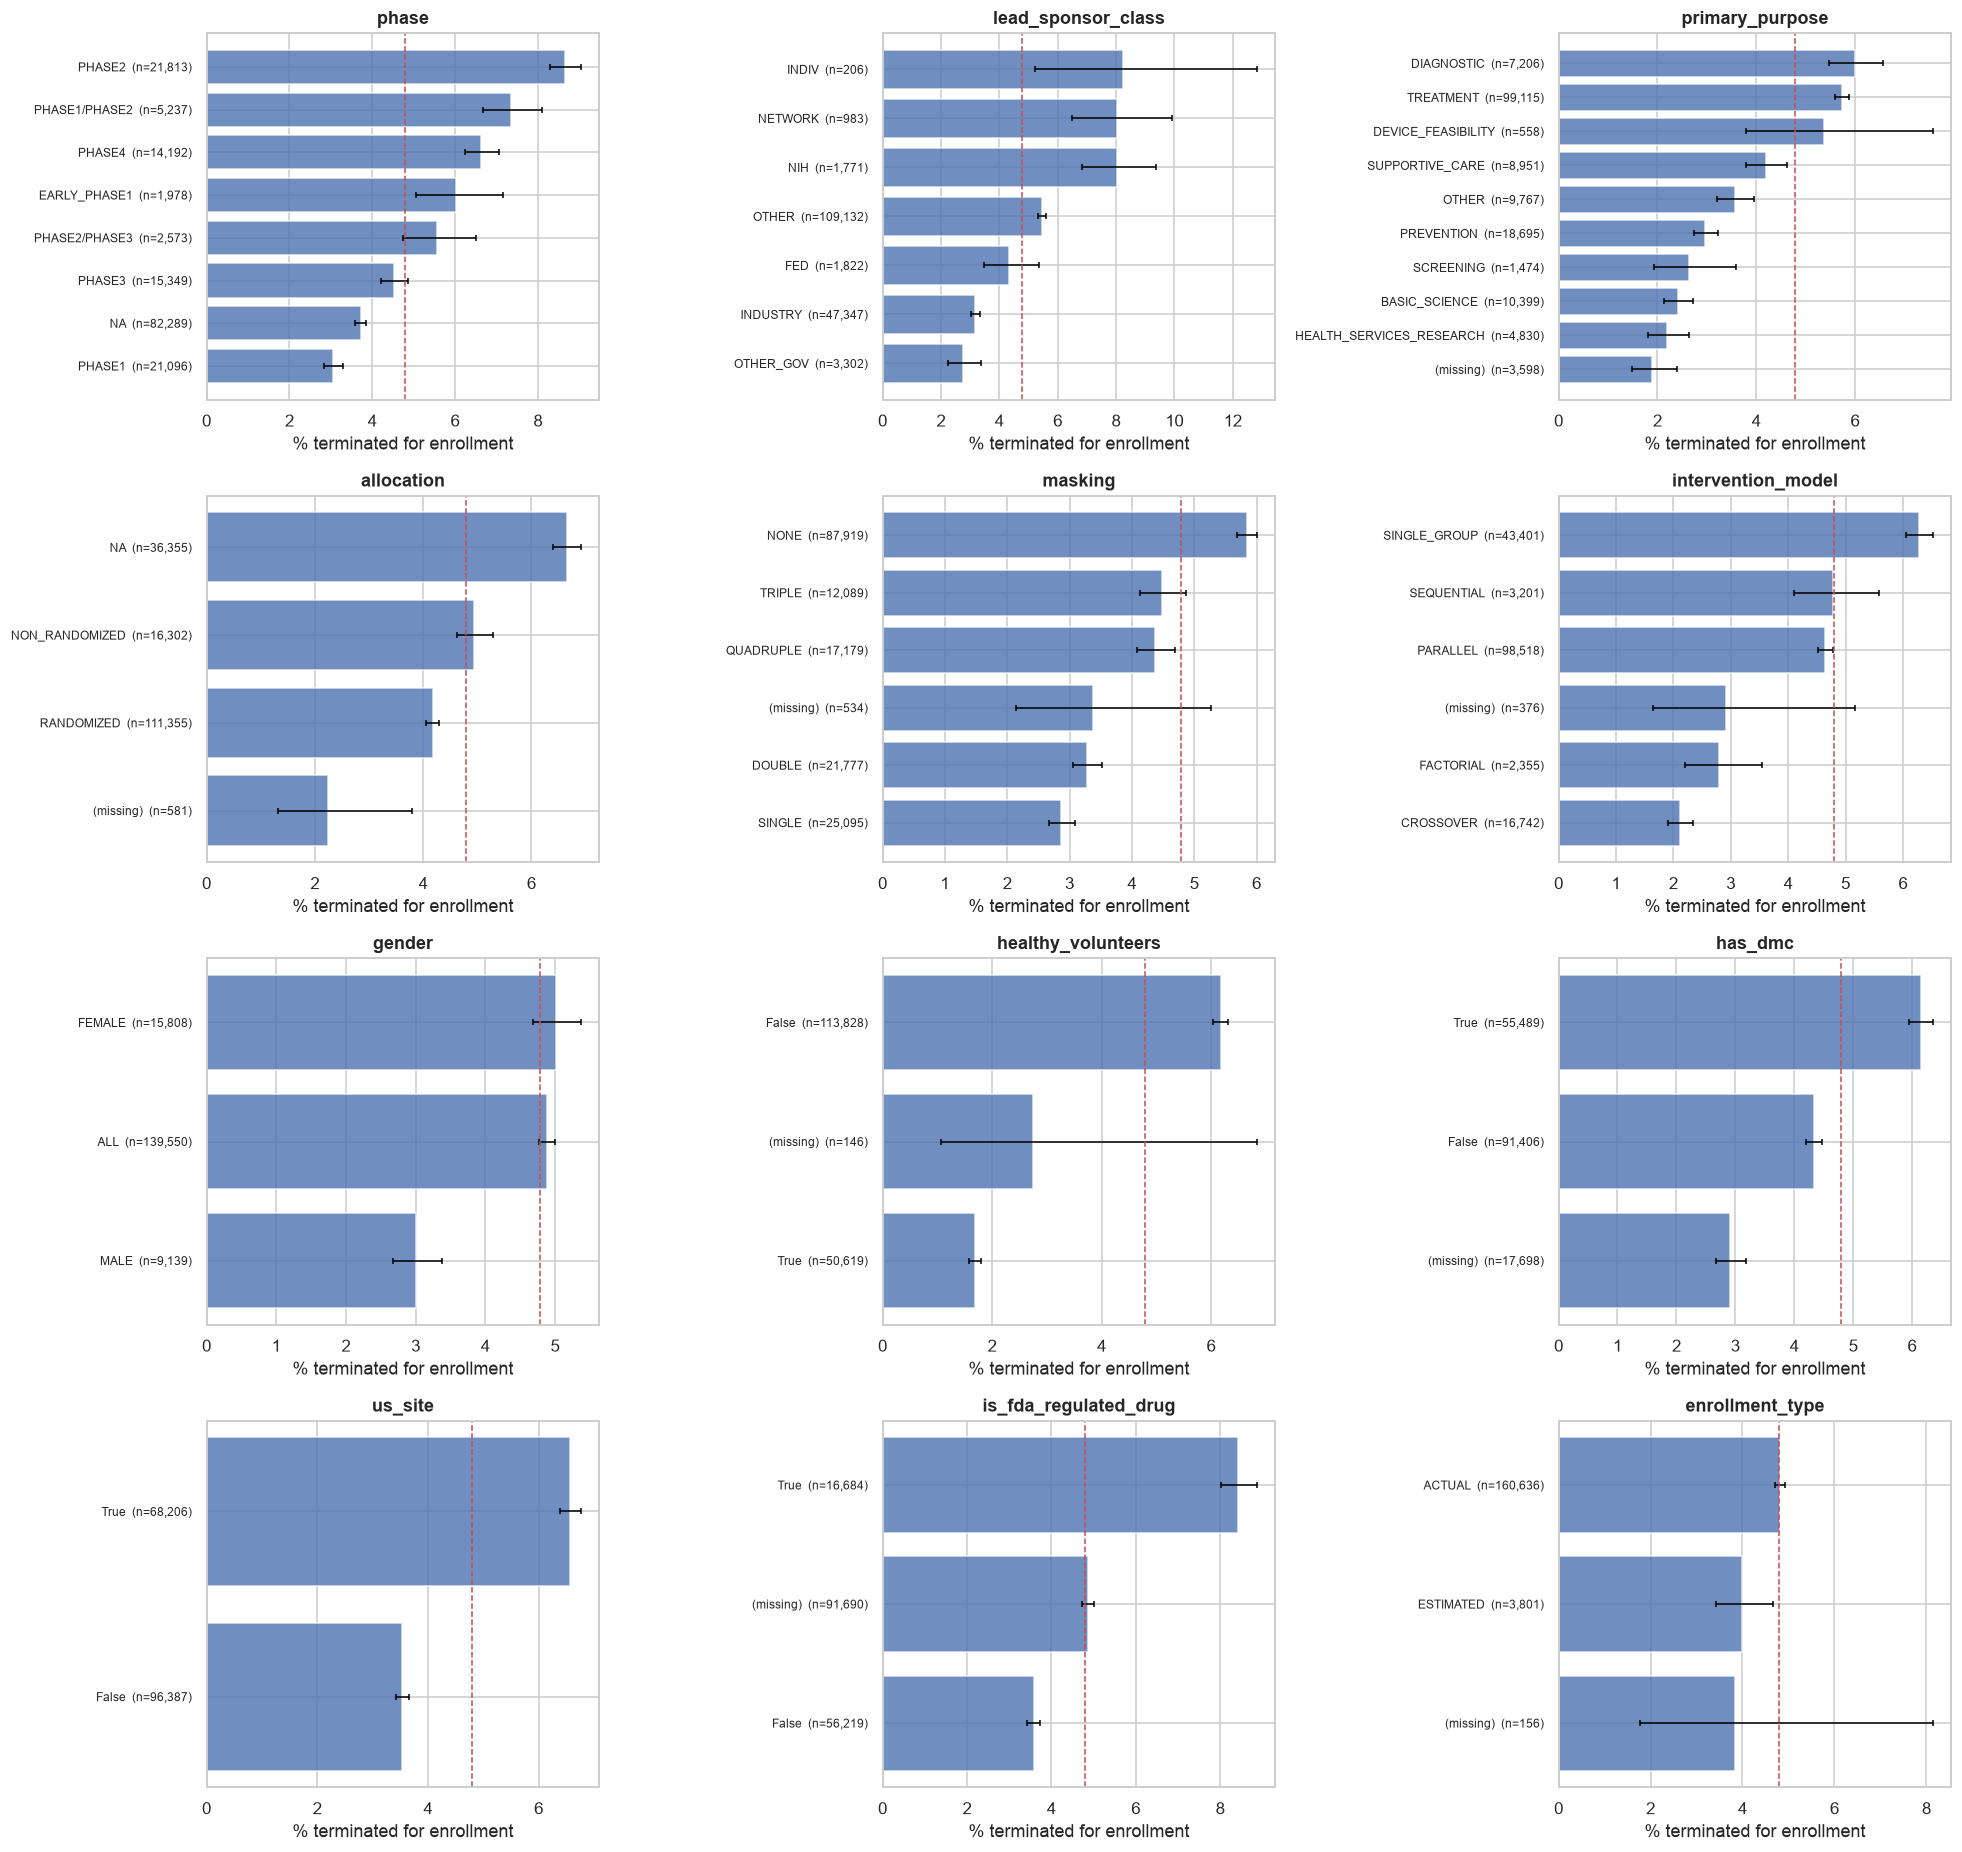

In [10]:
BASE = labeled["label"].mean()

def wilson(k, n, z=1.96):
    p = k / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centre - half, centre + half

def rate_table(data, col, min_n=100):
    g = data.groupby(data[col].astype("object").fillna("(missing)"), dropna=False)["label"]
    t = g.agg(n="size", k="sum")
    t = t[t["n"] >= min_n]
    t["rate"] = t["k"] / t["n"]
    t["lo"], t["hi"] = wilson(t["k"], t["n"])
    return t.sort_values("rate")

def rate_plot(ax, data, col, min_n=100):
    t = rate_table(data, col, min_n)
    y = np.arange(len(t))
    ax.barh(y, t["rate"] * 100, color="#4C72B0", alpha=0.8)
    ax.errorbar(t["rate"] * 100, y, xerr=[(t["rate"] - t["lo"]) * 100, (t["hi"] - t["rate"]) * 100],
                fmt="none", ecolor="black", lw=1, capsize=2)
    ax.axvline(BASE * 100, ls="--", color="#C44E52", lw=1)
    ax.set_yticks(y, [f"{i}  (n={n:,})" for i, n in zip(t.index.astype(str), t["n"])], fontsize=8)
    ax.set_title(col); ax.set_xlabel("% terminated for enrollment")

cat_cols = ["phase", "lead_sponsor_class", "primary_purpose", "allocation", "masking",
            "intervention_model", "gender", "healthy_volunteers", "has_dmc", "us_site",
            "is_fda_regulated_drug", "enrollment_type"]
fig, axes = plt.subplots(4, 3, figsize=(18, 17))
for ax, col in zip(axes.flat, cat_cols):
    rate_plot(ax, labeled, col)
plt.tight_layout(); savefig("categorical_rates"); plt.show()

In [11]:
# Cramér's V: strength of association of each categorical feature with the label (0 = none, 1 = perfect)
def cramers_v(x, y):
    ct = pd.crosstab(x, y)
    n = ct.values.sum()
    expected = np.outer(ct.sum(axis=1), ct.sum(axis=0)) / n
    chi2 = ((ct.values - expected) ** 2 / expected).sum()
    return np.sqrt(chi2 / (n * (min(ct.shape) - 1)))

pd.Series({c: cramers_v(labeled[c].astype("object").fillna("(missing)"), labeled["label"])
           for c in cat_cols}).sort_values(ascending=False).round(3).to_frame("cramers_v")

,cramers_v
healthy_volunteers,0.097
phase,0.087
us_site,0.070
primary_purpose,0.064
is_fda_regulated_drug,0.064
masking,0.057
intervention_model,0.055
lead_sponsor_class,0.054
has_dmc,0.049
allocation,0.048


## 6. Numeric features

Counts are heavily right-skewed, so distributions are shown on a log scale.
Ages are parsed from strings like `"18 Years"` / `"6 Months"` into years.

In [12]:
UNIT_TO_YEARS = {"year": 1, "month": 1 / 12, "week": 1 / 52.18, "day": 1 / 365.25,
                 "hour": 1 / 8766, "minute": 1 / 525960}

def age_years(s):
    if not isinstance(s, str):
        return np.nan
    m = re.match(r"\s*([\d.]+)\s*([a-z]+?)s?\s*$", s.lower())
    if not m or m.group(2) not in UNIT_TO_YEARS:
        return np.nan
    return float(m.group(1)) * UNIT_TO_YEARS[m.group(2)]

for d in (df, labeled):
    d["min_age_yrs"] = d["minimum_age"].map(age_years)
    d["max_age_yrs"] = d["maximum_age"].map(age_years)
    d["has_max_age"] = d["maximum_age"].notna()
    d["age_span_yrs"] = d["max_age_yrs"] - d["min_age_yrs"].fillna(0)
    d["n_collaborators"] = d["n_collaborators"].fillna(0)  # missing = none

unparsed = df["minimum_age"].notna() & df["min_age_yrs"].isna()
print("Unparsed minimum_age values:", df.loc[unparsed, "minimum_age"].unique()[:10])

num_cols = ["criteria_n_chars", "number_of_arms", "n_conditions", "n_interventions", "n_collaborators",
            "min_age_yrs", "max_age_yrs", "enrollment", "n_countries", "n_facilities"]
df[num_cols].describe(percentiles=[.01, .25, .5, .75, .99]).T.round(1)

Unparsed minimum_age values: <ArrowStringArray>
[]
Length: 0, dtype: str


,count,mean,std,min,1%,25%,50%,75%,99%,max
criteria_n_chars,231767.0,1581.6,1772.3,5.0,120.0,493.0,921.0,1969.0,8665.0,19987.0
number_of_arms,228851.0,2.2,1.4,1.0,1.0,2.0,2.0,2.0,8.0,45.0
n_conditions,231776.0,1.7,2.0,1.0,1.0,1.0,1.0,2.0,8.0,145.0
n_interventions,231776.0,2.0,1.4,1.0,1.0,1.0,2.0,2.0,7.0,97.0
n_collaborators,231776.0,0.6,1.5,0.0,0.0,0.0,0.0,1.0,6.0,128.0
min_age_yrs,222073.0,19.9,11.0,0.0,0.1,18.0,18.0,18.0,65.0,100.0
max_age_yrs,131700.0,58.3,25.2,0.0,0.2,45.0,65.0,75.0,100.0,200.0
enrollment,231538.0,1464.1,297616.5,0.0,0.0,24.0,56.0,136.0,3306.0,99999999.0
n_countries,212931.0,1.6,2.7,1.0,1.0,1.0,1.0,1.0,16.0,59.0
n_facilities,212931.0,7.8,37.0,1.0,1.0,1.0,1.0,2.0,131.0,1745.0


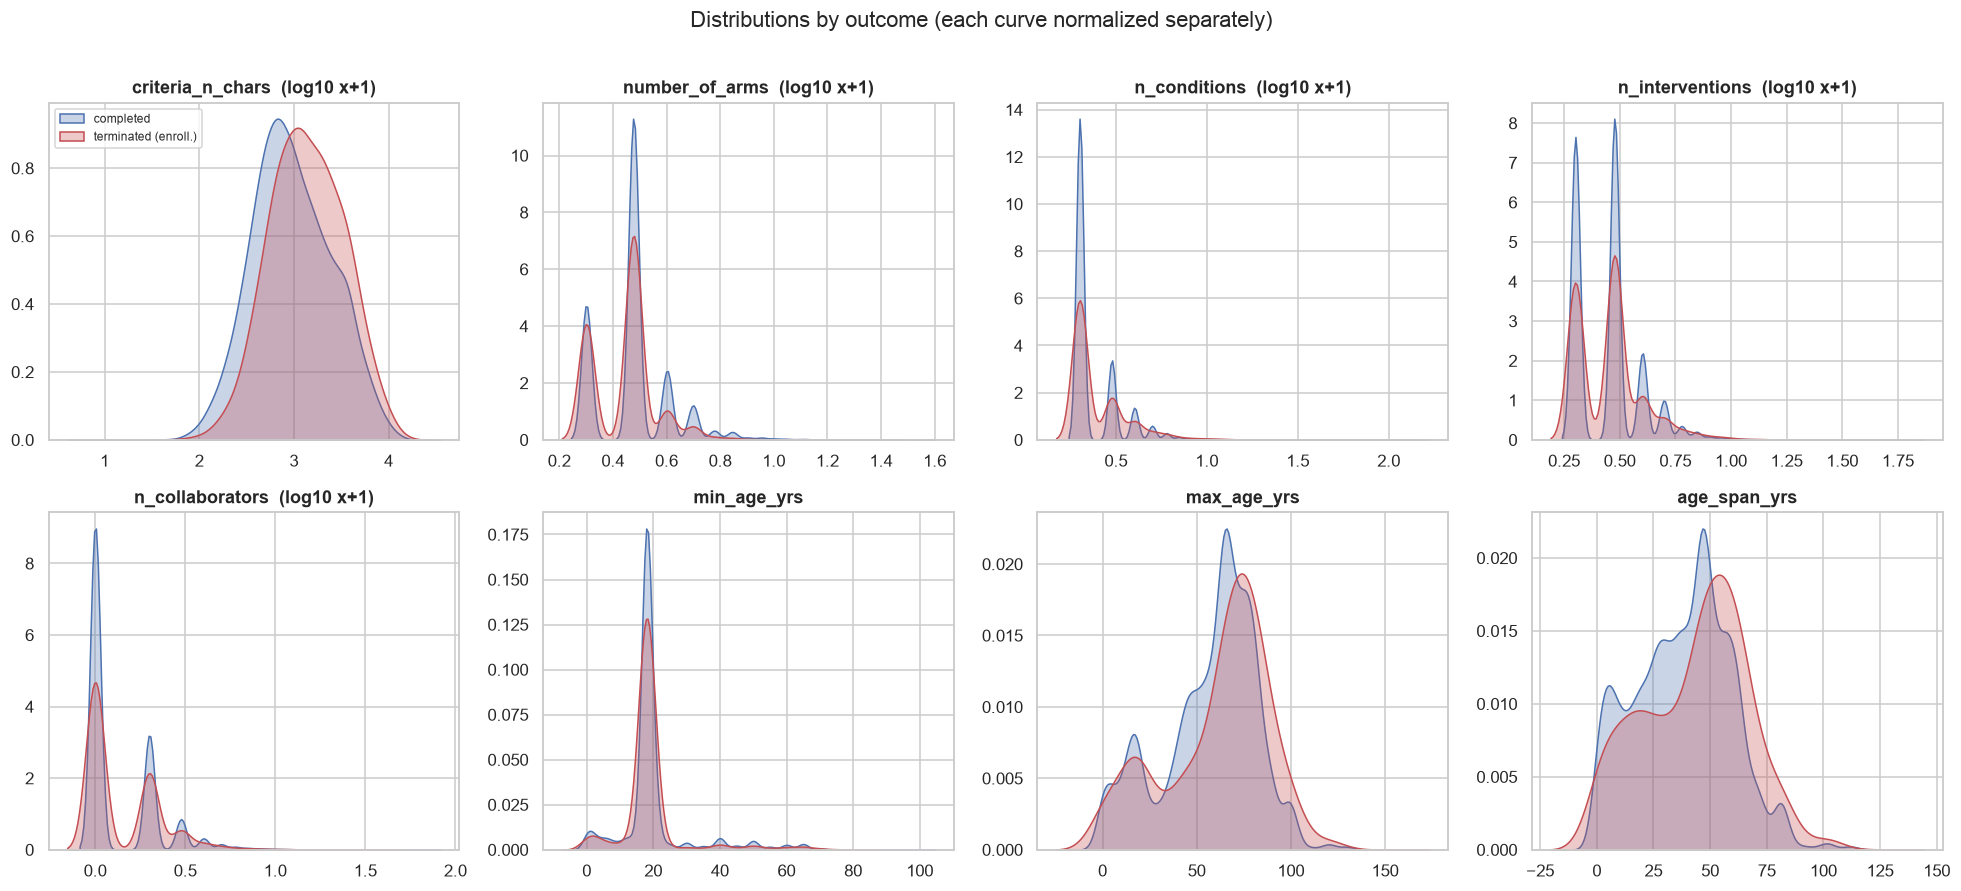

In [13]:
plot_cols = ["criteria_n_chars", "number_of_arms", "n_conditions", "n_interventions",
             "n_collaborators", "min_age_yrs", "max_age_yrs", "age_span_yrs"]
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.flat, plot_cols):
    for val, color, name in [(0, "#4C72B0", "completed"), (1, "#C44E52", "terminated (enroll.)")]:
        x = labeled.loc[labeled["label"] == val, col].dropna()
        log = col not in ("min_age_yrs", "max_age_yrs", "age_span_yrs")
        if log:
            x = np.log10(x + 1)
        sns.kdeplot(x, ax=ax, color=color, fill=True, alpha=0.3, common_norm=False, label=name, bw_adjust=1.5)
    ax.set_title(col + ("  (log10 x+1)" if log else ""))
    ax.set_xlabel(""); ax.set_ylabel("")
axes[0, 0].legend(fontsize=8)
fig.suptitle("Distributions by outcome (each curve normalized separately)", y=1.01)
plt.tight_layout(); savefig("numeric_by_label"); plt.show()

In [14]:
# Median and mean of each numeric feature by label
labeled.groupby("label")[plot_cols].agg(["median", "mean"]).T.unstack().round(1)

label               0.0             1.0        
                 median    mean  median    mean
criteria_n_chars  890.0  1528.8  1323.0  2007.1
number_of_arms      2.0     2.2     2.0     1.9
n_conditions        1.0     1.6     1.0     1.9
n_interventions     2.0     2.0     2.0     2.0
n_collaborators     0.0     0.6     0.0     0.6
min_age_yrs        18.0    20.0    18.0    19.2
max_age_yrs        65.0    56.9    69.5    61.0
age_span_yrs       40.0    38.1    47.0    43.6

## 7. Eligibility criteria — first look

The project hypothesis is that stricter or more complex eligibility makes recruiting harder.
`criteria_n_chars` (length of the free-text criteria) is a crude complexity proxy until the NLP features exist.

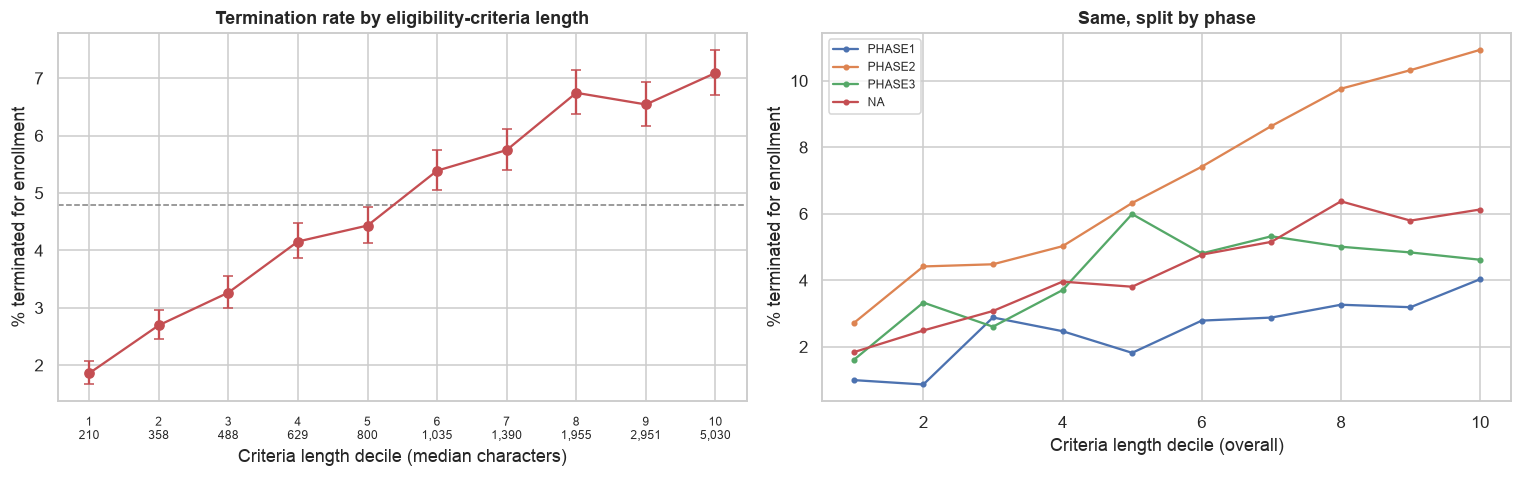

,median_chars,n,k,rate,lo,hi
criteria_decile,,,,,,
1,210.0,16517,307.0,0.019,0.017,0.021
2,358.0,16438,443.0,0.027,0.025,0.030
3,488.0,16539,540.0,0.033,0.030,0.035
4,629.0,16414,682.0,0.042,0.039,0.045
5,800.0,16421,728.0,0.044,0.041,0.048
6,1035.0,16439,886.0,0.054,0.051,0.057
7,1390.0,16454,946.0,0.057,0.054,0.061
8,1955.0,16453,1110.0,0.067,0.064,0.071
9,2951.0,16459,1077.0,0.065,0.062,0.069


In [15]:
labeled["criteria_decile"] = pd.qcut(labeled["criteria_n_chars"], 10, labels=False, duplicates="drop").astype("Int64") + 1
dec = labeled.groupby("criteria_decile").agg(
    median_chars=("criteria_n_chars", "median"), n=("label", "size"), k=("label", "sum"))
dec["rate"] = dec["k"] / dec["n"]
dec["lo"], dec["hi"] = wilson(dec["k"], dec["n"])

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].errorbar(dec.index, dec["rate"] * 100, yerr=[(dec["rate"] - dec["lo"]) * 100, (dec["hi"] - dec["rate"]) * 100],
                 marker="o", color="#C44E52", capsize=3)
axes[0].axhline(BASE * 100, ls="--", color="gray", lw=1)
axes[0].set_xticks(dec.index, [f"{d}\n{int(m):,}" for d, m in zip(dec.index, dec["median_chars"])], fontsize=8)
axes[0].set_xlabel("Criteria length decile (median characters)")
axes[0].set_ylabel("% terminated for enrollment")
axes[0].set_title("Termination rate by eligibility-criteria length")

# Is the length effect just a phase effect? Repeat within the main phases.
for ph in ["PHASE1", "PHASE2", "PHASE3", "NA"]:
    sub = labeled[labeled["phase"] == ph]
    r = sub.groupby("criteria_decile")["label"].mean() * 100
    axes[1].plot(r.index, r.values, marker=".", label=ph)
axes[1].set_xlabel("Criteria length decile (overall)")
axes[1].set_ylabel("% terminated for enrollment")
axes[1].set_title("Same, split by phase")
axes[1].legend(fontsize=8)
plt.tight_layout(); savefig("criteria_length"); plt.show()
dec.round(3)

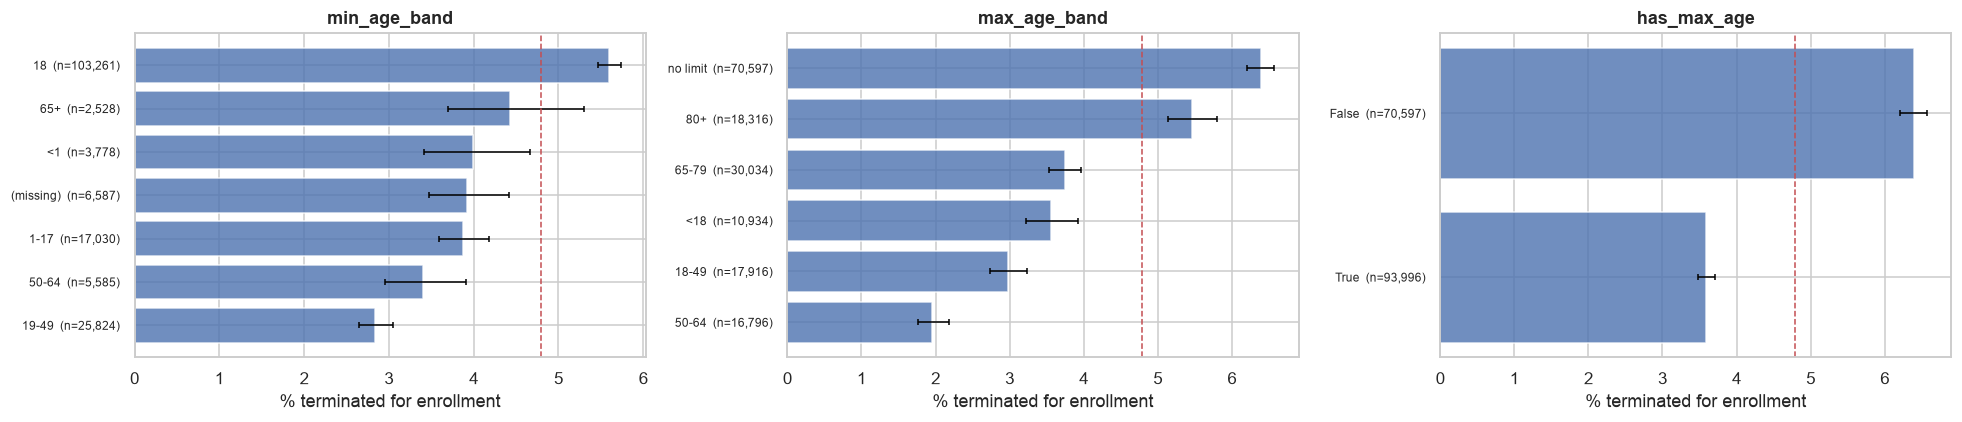

In [16]:
# Age limits
labeled["min_age_band"] = pd.cut(labeled["min_age_yrs"], [-0.01, 0.99, 17.99, 18.01, 49.99, 64.99, 200],
                                 labels=["<1", "1-17", "18", "19-49", "50-64", "65+"])
labeled["max_age_band"] = pd.cut(labeled["max_age_yrs"], [-0.01, 17.99, 49.99, 64.99, 79.99, 200],
                                 labels=["<18", "18-49", "50-64", "65-79", "80+"]).astype("object").fillna("no limit")
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, col in zip(axes, ["min_age_band", "max_age_band", "has_max_age"]):
    rate_plot(ax, labeled, col)
plt.tight_layout(); savefig("age_limits"); plt.show()

In [17]:
# Peek at criteria text for a short and a long example
full = df[df["label"].notna()]
for q in (0.1, 0.9):
    row = full.iloc[(full["criteria_n_chars"] - full["criteria_n_chars"].quantile(q)).abs().argmin()]
    print(f"=== {row.nct_id}  ({int(row.criteria_n_chars)} chars, label={int(row.label)}) ===")
    print(row.criteria[:800], "\n")

=== NCT01477996  (289 chars, label=0) ===
Inclusion Criteria:

* vitrearetinal disease including age-related macular degeneration,
* clinical significant macular edema due to diabetic retinopathy or other vascular disorders
* treatment with intravitreal therapy

Exclusion Criteria:

* missing informed consent
* age under 50 years 

=== NCT04264143  (3716 chars, label=0) ===
Inclusion Criteria:

* Aged more than 3 years up to the 18th birthday
* Radiological diagnosis of DIPG with tumor confined to the region of the pons or
* thalami without cystic changes or hematoma obstructing the planned catheter trajectories
* Radiological diagnosis of thalamic gliomas confined to bilateral thalami without cystic changes or hematoma obstructing the planned catheter trajectories
* Radiological features of DIPG: intrinsic, pontine based infiltrative lesion; hypointense in T1 weighted images (T1WIs) and hyperintense in T2 sequences, with mass effect on the adjacent structures and occupying at least 50

## 8. Interactions worth noting

Phase × sponsor class: industry and academic trials may behave differently at the same phase.

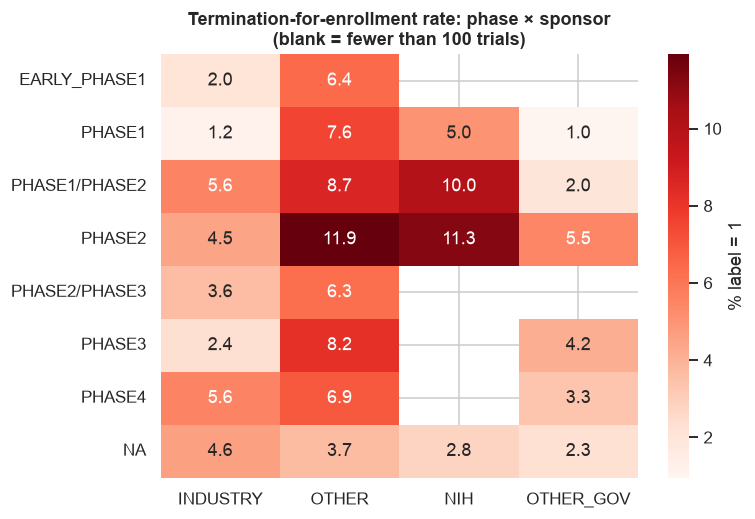

In [18]:
pivot = labeled.pivot_table(index="phase", columns="lead_sponsor_class", values="label",
                            aggfunc=["mean", "size"])
rates = pivot["mean"][["INDUSTRY", "OTHER", "NIH", "OTHER_GOV"]] * 100
ns = pivot["size"][["INDUSTRY", "OTHER", "NIH", "OTHER_GOV"]]
rates = rates.where(ns >= 100)  # hide unstable cells
order = ["EARLY_PHASE1", "PHASE1", "PHASE1/PHASE2", "PHASE2", "PHASE2/PHASE3", "PHASE3", "PHASE4", "NA"]
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(rates.reindex(order), annot=True, fmt=".1f", cmap="Reds", cbar_kws={"label": "% label = 1"}, ax=ax)
ax.set_title("Termination-for-enrollment rate: phase × sponsor\n(blank = fewer than 100 trials)")
ax.set_xlabel(""); ax.set_ylabel("")
savefig("phase_x_sponsor"); plt.show()

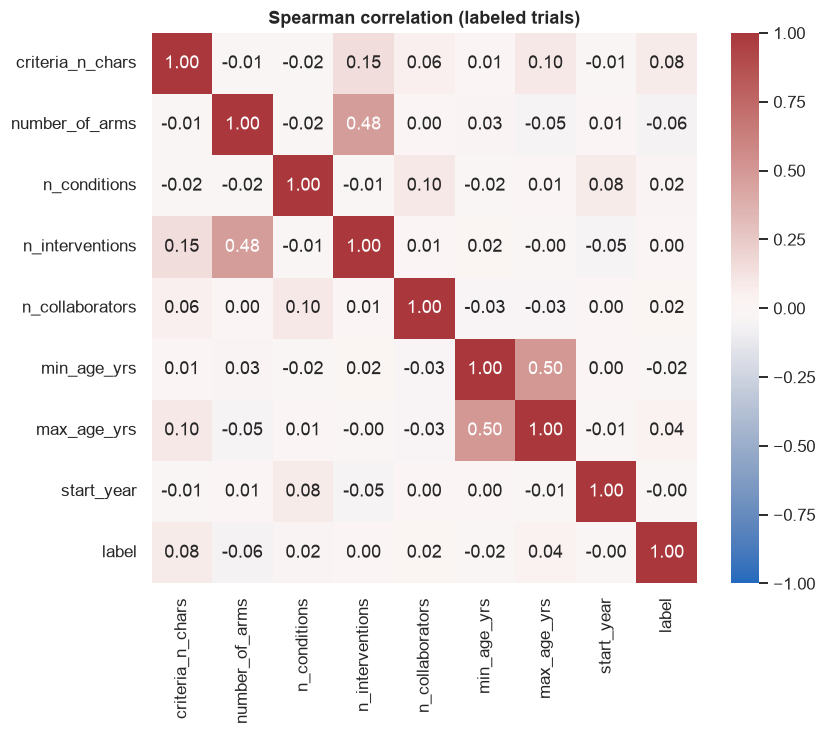

In [19]:
# Correlation among (non-leaky) numeric features — check for redundancy
corr_cols = ["criteria_n_chars", "number_of_arms", "n_conditions", "n_interventions", "n_collaborators",
             "min_age_yrs", "max_age_yrs", "start_year", "label"]
corr = labeled[corr_cols].corr(method="spearman")
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Spearman correlation (labeled trials)")
savefig("correlation"); plt.show()

## 9. Leakage check

The README flags `enrollment`, `enrollment_type`, `completion_date`, `n_facilities` and `n_countries`
as reflecting the trial's **final** state. The plots below show how strongly they separate the classes —
far more than any legitimate feature — which confirms they must not be used as-is.

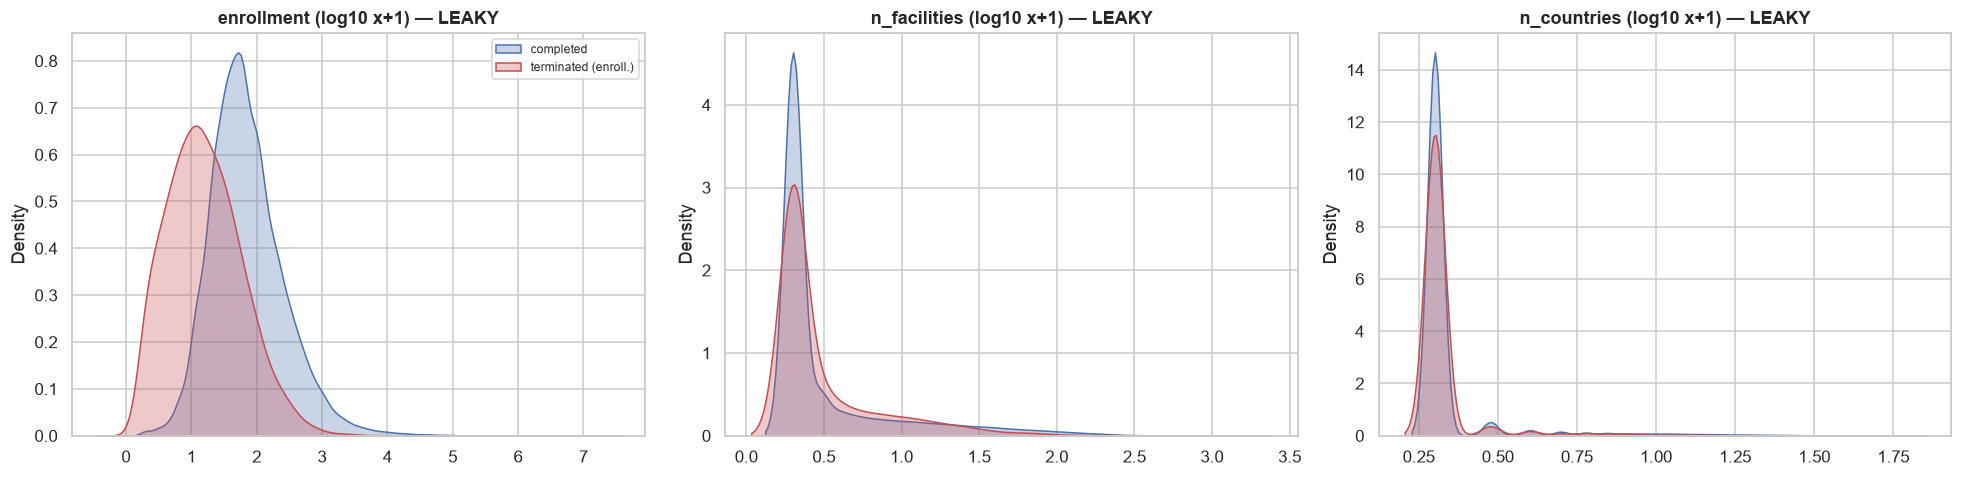

label              0.0    1.0
enrollment_type              
ACTUAL           0.977  0.981
ESTIMATED        0.023  0.019

Median actual enrollment by label:
label
0.0    60.0
1.0    13.0
Name: enrollment, dtype: float64


In [20]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, col in zip(axes, ["enrollment", "n_facilities", "n_countries"]):
    for val, color, name in [(0, "#4C72B0", "completed"), (1, "#C44E52", "terminated (enroll.)")]:
        x = np.log10(labeled.loc[labeled["label"] == val, col].dropna() + 1)
        sns.kdeplot(x, ax=ax, color=color, fill=True, alpha=0.3, label=name, bw_adjust=1.5)
    ax.set_title(f"{col} (log10 x+1) — LEAKY"); ax.set_xlabel("")
axes[0].legend(fontsize=8)
plt.tight_layout(); savefig("leakage"); plt.show()

print(pd.crosstab(labeled["enrollment_type"], labeled["label"], normalize="columns").round(3))
print("\nMedian actual enrollment by label:")
print(labeled.groupby("label")["enrollment"].median())

## 10. Data quality issues

In [21]:
issues = {
    "enrollment >= 1,000,000 (placeholder values like 99999999)": (df["enrollment"] >= 1e6).sum(),
    "enrollment == 0": (df["enrollment"] == 0).sum(),
    "completion_date before start_date": (pd.to_datetime(df["completion_date"], errors="coerce") < df["start_date"]).sum(),
    "min_age > max_age": (df["min_age_yrs"] > df["max_age_yrs"]).sum(),
    "criteria shorter than 50 chars": (df["criteria_n_chars"] < 50).sum(),
    "phase missing": df["phase"].isna().sum(),
    "TERMINATED with no why_stopped": ((df["overall_status"] == "TERMINATED") & df["why_stopped"].isna()).sum(),
    "COMPLETED with enrollment_type ESTIMATED": ((df["overall_status"] == "COMPLETED") & (df["enrollment_type"] == "ESTIMATED")).sum(),
}
pd.Series(issues).to_frame("n_trials")

,n_trials
"enrollment >= 1,000,000 (placeholder values like 99999999)",12
enrollment == 0,8097
completion_date before start_date,26
min_age > max_age,0
criteria shorter than 50 chars,56
phase missing,84
TERMINATED with no why_stopped,1736
COMPLETED with enrollment_type ESTIMATED,3649


In [22]:
print("Largest enrollment values:")
print(df.nlargest(8, "enrollment")[["nct_id", "overall_status", "enrollment", "enrollment_type", "primary_purpose"]].to_string(index=False))

Largest enrollment values:
     nct_id        overall_status  enrollment enrollment_type          primary_purpose
NCT01912313            RECRUITING  99999999.0       ESTIMATED            BASIC_SCIENCE
NCT02421705            RECRUITING  99999999.0       ESTIMATED            BASIC_SCIENCE
NCT02361008             COMPLETED  20121212.0          ACTUAL                TREATMENT
NCT03411785               UNKNOWN   5326531.0       ESTIMATED HEALTH_SERVICES_RESEARCH
NCT04184544               UNKNOWN   5000000.0       ESTIMATED HEALTH_SERVICES_RESEARCH
NCT01081288 ACTIVE_NOT_RECRUITING   4000000.0       ESTIMATED               PREVENTION
NCT04053075             COMPLETED   2905455.0          ACTUAL               PREVENTION
NCT03090321 ACTIVE_NOT_RECRUITING   2000000.0       ESTIMATED               PREVENTION


## 11. Summary of findings

**Data**
- 231,776 interventional trials (start 2008–2020), one row each, no duplicate IDs.
- 7,886 positives vs 156,707 completed → **4.8% positive rate (about 1 positive per 20 negatives)**. Plan for class imbalance (PR-AUC rather than accuracy, class weights).
- 67,183 trials (29%) have no label. The largest group is `UNKNOWN` status (38k), and it grows from about 9% of 2008 starts to about 25% of 2020 starts. Excluding them may bias the labeled set; this needs a check in the competing-risks analysis.

**Outcome**
- Enrollment is the **most common reason for termination** (7,886 of 20,039, 39%).
- The v0 keyword classifier mostly works, but the spot-check shows problems: multi-reason texts ("slow enrollment and PI departure"), staffing problems caught by "recruit", and some patient-population texts ending up in `other`. Validating it against hand labels matters.
- The positive rate is stable over time (4.5–5.4%), so start year is not a strong signal on its own.

**Associations with label = 1 (bivariate, not adjusted)**
- **Eligibility criteria length shows the clearest gradient**: 1.9% in the shortest decile to 7.1% in the longest, increasing almost steadily. The trend holds within Phase 2 (2.7% → 10.9%) and NA-phase trials, and is weaker in Phase 1 and Phase 3. This is early support for the eligibility hypothesis, but criteria length is also tied to disease area (e.g. oncology), which has not been adjusted for yet.
- **Healthy volunteers** is the strongest single categorical signal (Cramér's V 0.10): 1.7% vs 6.2% for patient-only trials.
- **Phase**: Phase 2 is highest (8.6%) and Phase 1 lowest (3.0%).
- **Sponsor**: industry is low (3.1%); academic/other (5.4%), NIH (8%) and network (8%) are higher. Phase × sponsor matters: academic Phase 2 reaches 11.9% while industry Phase 2 is 4.5%.
- **Design**: open-label, single-group and non-randomized trials are higher; crossover trials are low (2.1%).
- **US site** (6.6% vs 3.5%) and **FDA-regulated drug** (8.4% vs 3.6%) are higher. Both may reflect how complete the registration is rather than true risk. Also, `us_site` comes from the country table and can change over the trial, so it is potentially leaky.
- Trials with an upper age limit and male-only trials have lower rates. Positive trials have slightly wider age spans (median 47 vs 40 years).
- All associations are modest individually (Cramér's V ≤ 0.10), so a model will need to combine many weak signals.

**Leakage (confirmed)**
- Median actual enrollment is 13 for terminated trials vs 60 for completed. `n_facilities` / `n_countries` also separate the classes strongly. Keep these out of the feature set.
- `enrollment_type` is about 98% `ACTUAL` in both classes, so it carries no information for labeled trials.

**Data quality to fix in the pipeline**
- `n_collaborators` NaN means 0; `maximum_age` NaN means "no limit"; `is_fda_regulated_*` is about 90% missing before 2017 (the field did not exist yet).
- 12 enrollment values ≥ 1M (placeholders such as 99,999,999), 8,097 with enrollment 0, and 26 trials whose completion date is before the start date.
- 1,736 terminated trials have no `why_stopped`, so their reason can never be known.

**Next steps**
1. Validate `stop_reason` against hand labels.
2. Add a therapeutic-area feature (from `browse_conditions`) and re-check the criteria-length effect within it.
3. Fit a multivariable baseline (logistic regression) on the non-leaky features to see which associations survive adjustment.
4. Build NLP features from the criteria text: number of inclusion/exclusion items, lab thresholds, prior-therapy restrictions.